# OT Flow Matching

In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
from generative_models.data import MoonsCirclesDataset
import matplotlib.pyplot as plt
from generative_models.trainer import OTFlowMatchingTrainer
from generative_models.model import FlowMatchingMLP

config = {
    'lr': 1e-3,
    'batch_size': 1000,
    'total_steps': 10000,
    'log': True,
    'project': 'OTFlowMatching',
    'name': 'mlp_lr_1e-3'
}

dataset = MoonsCirclesDataset(n_samples=100000, noise_moons=0.05, noise_circles=0.04)
model = FlowMatchingMLP(2, [64, 64, 64, 2])
trainer = OTFlowMatchingTrainer(model, dataset, config)

trainer.train()

loss,▄▆▄▄▄▅▅▆▅▁▆▅▆█▄▄▅▂▅▅▇▄▄▆▅▄▆▆▇▃▆▅▅▇▇▅▂▅▅▅
loss,1.54917


100%|██████████| 10000/10000 [00:28<00:00, 347.29it/s, loss=1.02]


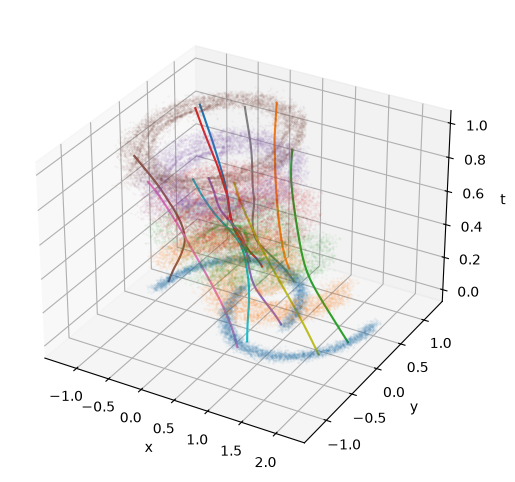

In [32]:
from generative_models.data import MoonsDataset
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

One step generation.

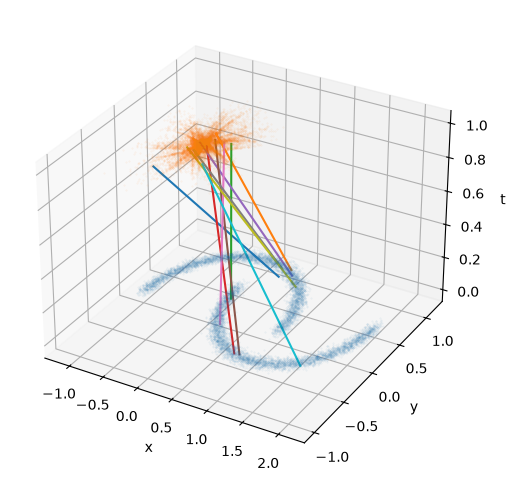

In [33]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.zeros((b, 2))
t[:, 1] = 1 # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [0, 1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Two step generation.

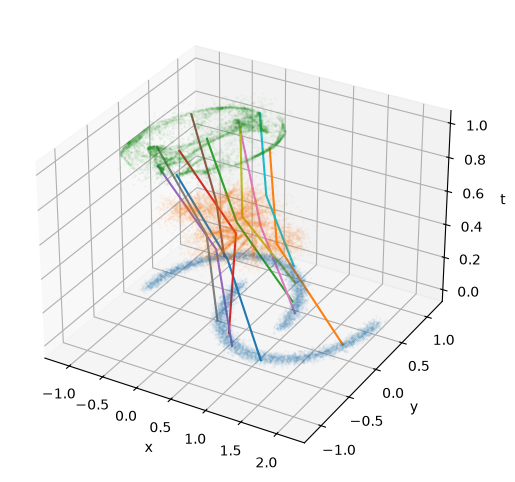

In [34]:
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.zeros((b, 3))
t[:, 1] = 0.5 # shape (b, l)
t[:, 2] = 1.0

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [0, 1, 2]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

Ablations: u(x, t) without t.

In [35]:
class FlowMatchingMLPNoT(FlowMatchingMLP):
    def forward(self, x, t):
        fake_t = torch.zeros_like(t)
        return self.mlp(torch.concat([x, fake_t], dim=1))

In [36]:
from generative_models.data import MoonsCirclesDataset
import matplotlib.pyplot as plt
from generative_models.trainer import OTFlowMatchingTrainer
from generative_models.model import FlowMatchingMLP

config = {
    'lr': 1e-3,
    'batch_size': 1000,
    'total_steps': 10000,
    'log': True,
    'project': 'OTFlowMatching',
    'name': 'mlp_lr_1e-3_no_T'
}

dataset = MoonsCirclesDataset(n_samples=100000, noise_moons=0.05, noise_circles=0.04)
model = FlowMatchingMLPNoT(2, [64, 64, 64, 2])
trainer = OTFlowMatchingTrainer(model, dataset, config)

trainer.train()

loss,█▆▇▅▆▆▅▄▅▄▄▄▃▄▄▄▅▂▁▃▂▅▃▅▃▂▂▄▄▃▂▂▂▂▁▄▃▃▄▃
loss,1.02262


100%|██████████| 10000/10000 [00:29<00:00, 343.79it/s, loss=1.53]


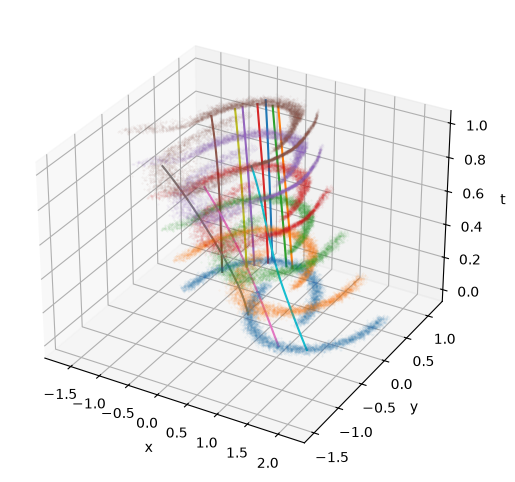

In [44]:
from generative_models.data import MoonsDataset
from generative_models.de import NeuralODE, Euler
import torch
import matplotlib.pyplot as plt

b = 10000
l = 100

dataset = MoonsDataset(n_samples=b, noise=0.05)
x0 = dataset.x
t = torch.linspace(0, 1, l)[None, :].expand(b, l)   # shape (b, l)

ode = NeuralODE(model)
euler = Euler(ode=ode)

x0 = x0.to(trainer.device)
t = t.to(trainer.device)
with torch.no_grad():
    x_pred = euler.simulate_trajectory(x0, t, whole=True)   # shape (b, l, d)
x_pred = x_pred.cpu().numpy()
t = t.cpu().numpy()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

# Draw the simulated flow.
for i in [*range(0, l-1, 20), l-1]:
    ax.scatter(
        x_pred[:, i, 0],
        x_pred[:, i, 1],
        t[:, i],
        s=0.1,
        alpha=0.1,
        depthshade=False
    )

# Draw the simulated trajectories.
for i in range(0, b, b//10):
    ax.plot(
        x_pred[i, :, 0],
        x_pred[i, :, 1],
        t[i, :]
    )

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("t")
plt.show()

In high dimensions the result is different. Sun et al. (2025) removed t from image models. On CIFAR-10, flow matching with 100 Euler steps got FID (Fréchet Inception Distance) 3.01 with t and 2.61 without t. Their reason is that in high dimensions, x_t itself tells the value of t. Our data has only 2 dimensions, so x_t does not tell t.